## 1.1 Testing transforms and plotting 

In [1]:
import sys
sys.path.append('..')

import matplotlib.pyplot as plt
from scipy import signal
import plotly.graph_objects as go

import pywt
import numpy as np

from scipy.signal.windows import blackmanharris
import matplotlib.pyplot as plt

from wavelet_transform.utils import synthetic_data as sd
from wavelet_transform.wpt import transform as wpt
from wavelet_transform.postprocess import plotting as plot
from wavelet_transform.utils.extensions import sci_form
from wavelet_transform.wpt import inverse_transform as inv
import wavelet_transform.utils.bubble_data_manager as bdm

In [2]:
def full_plot(nodes, data, t_plot, sampling_rate, title="", frequencies=None):
    """
    Formatted charts for plotting the results from a dwt or dpwt. Combines
    relevant plots including those for the sound wave, frequency content of
    the sound wave (using synthetic data package), and plots of the data at
    each node.

    Parameters
    ----------
    nodes: list
        list of node objects
    data: array_like
        an array of the data from the sound wave
    t_plot: array_like
        the time array to plot the data against
    nyquist_frequency: float
        1/2*sampling rate
    frequencies: list
        list of floats containing the frequencies of the synthetic sound wave
        for the historgram
    """
    # plot data
    fig_1, ax_1 = plt.subplots()
    plot.plot_wave(data, t_plot, ax_1, title)

    # plot transform coefficients all at once
    if frequencies:  # plot a histogram of frequency content in data as well
        fig_2, ax_2 = plt.subplots(2)
        plot.plot_all_final_nodes(nodes, ax_2[0], title)
        plot.plot_frequencies(frequencies, ax_2[1], title)
    else:
        fig_2, ax_2 = plt.subplots()
        plot.plot_all_final_nodes(nodes, ax_2, title)

    # plot each node separately.
    rows = round(len(nodes) / 2)
    fig_3, ax_3 = plt.subplots(rows, 2)
    fig_3.set_size_inches(12, 3 * rows)
    plot.plot_nodes(nodes, ax_3, sampling_rate, rows, columns=2)

    fig_1.tight_layout()
    fig_2.tight_layout()
    fig_3.tight_layout()
    plt.show()

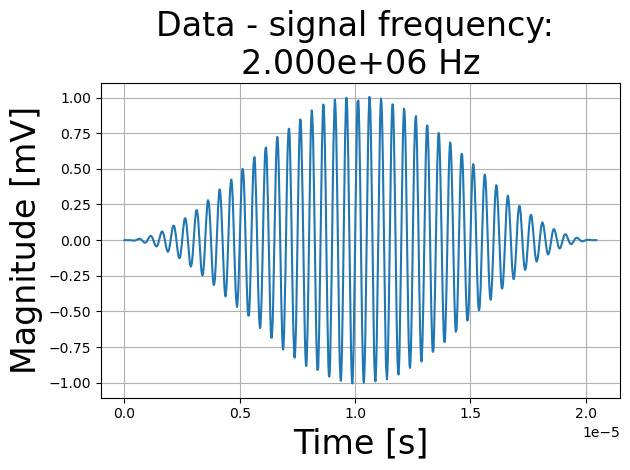

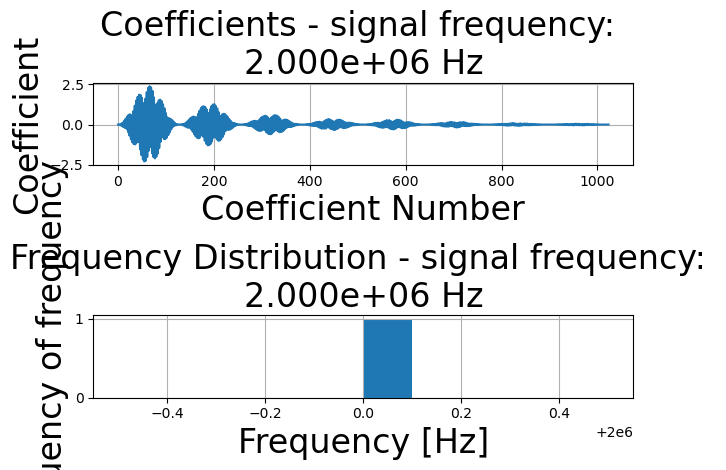

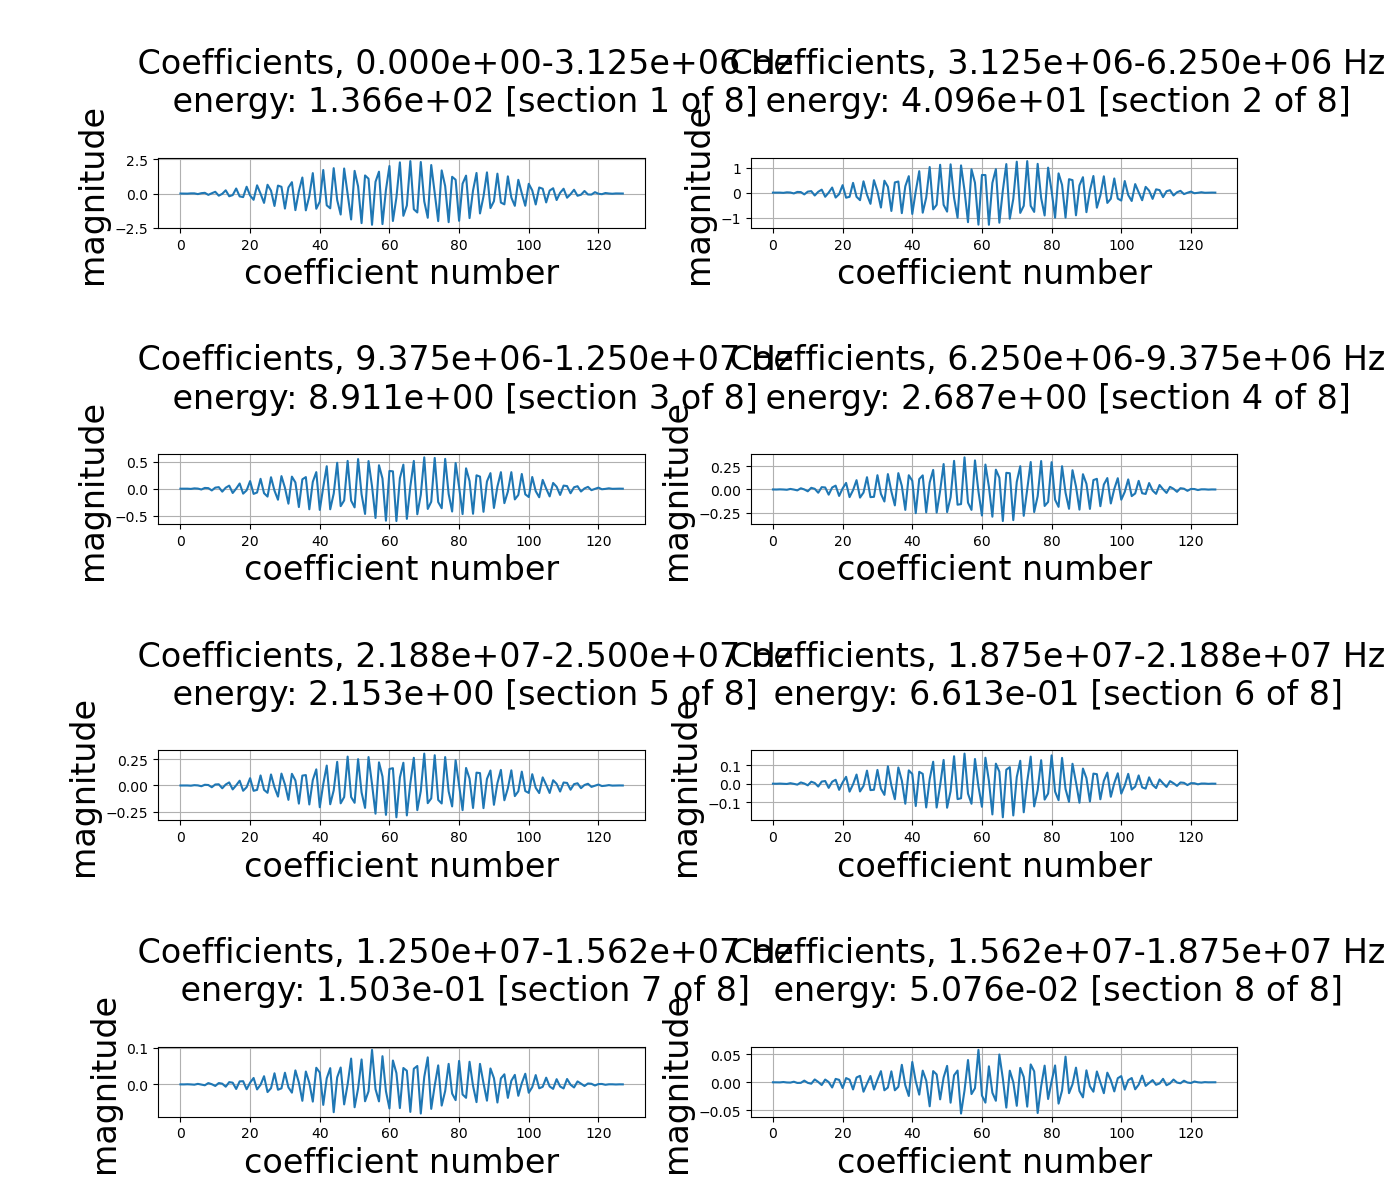

In [3]:
amp_sin_waves = 1 # amplitude of the sine waves added together to form the signal
sampling_rate = 50e6
phase = 0

frequency = 2e6

frequencies = [frequency] # create list of frequencies for synthetic data
time_period = 1/frequency
signal_duration = 100*time_period # duration of the signal is 10 times the test frequency
delay = 0#2*time_period # signal starts 2 time periods late
end = signal_duration#8*time_period # signal ends 2 time periods early

gaussian_noise_std = 0.01 # set the standard devaition of the noise

# generate data
data, t_plot = sd.sound_wave(
    amp_sin_waves, frequencies, phase, signal_duration, 
    sampling_rate, delay, end
    )

# add noise
gaussian_noise = sd.noise(gaussian_noise_std,signal_duration,sampling_rate)
data += gaussian_noise
data = data[:2**10]
t_plot = t_plot[:2**10]
data = signal.windows.hann(len(data))*data

# transform parameters
levels = 3
db_order = 1
wavelet = f'db{db_order}'
mode = "zero"

# transform
transform_object = wpt.dwpt(data,levels, wavelet, mode)
final_level_nodes = transform_object.get_level(levels)
dwt_nodes = transform_object.dwt_results() # the dwt results can be extracted from the dwpt

# calculate energy
transform_object.calc_frequencies(sampling_rate)

# set title
f = sci_form(frequency)
title = f"- signal frequency: \n{f} Hz"

# plot everything
full_plot(
    final_level_nodes, data, t_plot, sampling_rate, 
    title, frequencies
    )

### Total Energy
Calculating total energy at different levels

In [4]:
from wavelet_transform.utils.statistical_features import energy
t = np.linspace(0, 10, 1000)
data = np.sin(2 * np.pi * t)
data += np.random.normal(0, 1, len(t))
levels = 5
wavelet = "haar"
mode = "zero"
transform_object = wpt.dwpt(data, levels, wavelet, mode)

info = transform_object.info(level=levels, order="freq")
# total_energy = sum(info["energy"])
total_energy = sum(node.energy for node in transform_object.get_level())
total_energy_data = energy(data)
print("sum of node energy:", total_energy)
print("signal energy:", total_energy_data)
print("energy of each node:")
display(info["energy"])

total_energy_dwt = sum(node.energy for node in transform_object.dwt_results())
print("total dwt energy:", total_energy_dwt)

sum of node energy: 1488.332417031629
signal energy: 1488.3324170316278
energy of each node:


0     328.976992
1     118.754914
2      31.876039
3      58.495441
4      21.730402
5      37.866202
6      30.605377
7      41.054477
8      27.784806
9      24.378564
10     20.309359
11     26.372496
12     30.095360
13     32.764984
14     49.871950
15     29.726186
16     30.964961
17     31.090538
18     35.213453
19     51.979545
20     25.523599
21     44.474061
22     25.386547
23     39.461698
24     30.879438
25     35.422173
26     34.762441
27     41.395520
28     34.780574
29     43.228662
30     36.240802
31     36.864857
Name: energy, dtype: float64

total dwt energy: 1488.3324170316282


## 1.2 Testing with pywt library

In [5]:
def plot_test(nodes):
    """
    testing the wavelet transform in this library

    Parameters
    ----------
    nodes: list
        a list of node objects containing data to plot

    Returns
    -------
    output: array
        an array of the plotted data, a concatenation of the data from the
        provided nodes
    """

    # concatenate coefficients
    output = np.array([])
    for node in nodes:
        output = np.concatenate((output, node.data))
    # plot coefficients
    plt.plot(output)
    plt.grid(True)
    plt.show()

    return output

def plot_pywp_test(wp_object, levels, plot=True):
    """
    testing the transform from the python library

    Parameters
    ----------
    wp_object: object
        the object that comes from the function WaveletPacket()
    levels: int
        the level of transform to be plotted
    plot: boolean
        whether to plot or just return concatenated data

    Returns
    -------
    coeffs: array
        the data that was plotted,a concatenation of each of data from all nodes
        in the specified level
    """
    nodes = [node.path for node in wp_object.get_level(levels)]

    # concatenante coefficients
    coeffs = []
    for node in nodes:
        node_data = wp_object[node].data
        coeffs = np.concatenate((coeffs, node_data))

    # plot coefficients
    if plot:
        plt.plot(coeffs)
        plt.grid(True)
        plt.show()

    return coeffs

pywt result


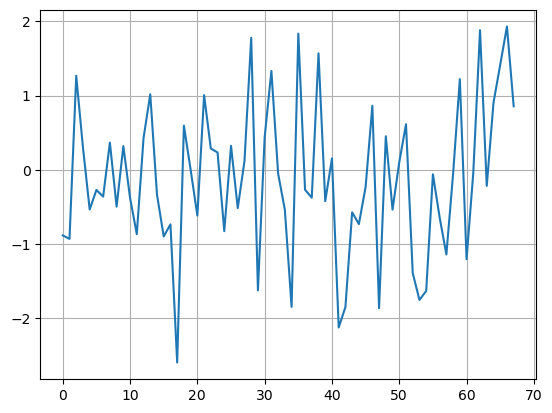

library result


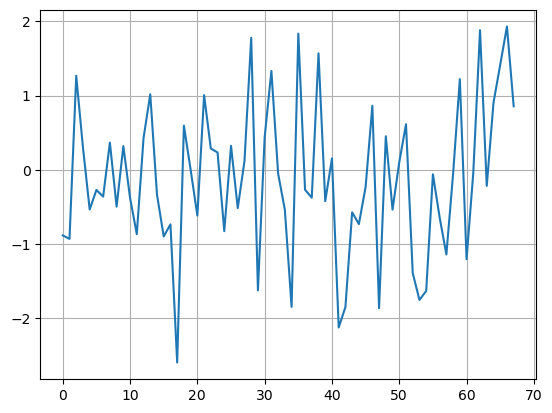

total error 2.8655463418791882e-15


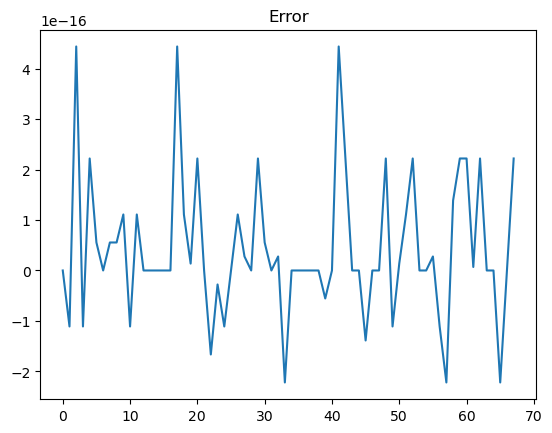

[-8.83331341e-01 -9.29933891e-01  1.26619914e+00  3.01226439e-01
 -5.34695543e-01 -2.71132392e-01 -3.61148625e-01  3.66384129e-01
 -4.95987198e-01  3.19298349e-01 -3.78777777e-01 -8.66811667e-01
  4.25890124e-01  1.01690952e+00 -3.33547984e-01 -8.97696561e-01
 -7.34291463e-01 -2.59452881e+00  5.94609664e-01  7.04245139e-04
 -6.16689696e-01  1.00590460e+00  2.86545947e-01  2.33532473e-01
 -8.26284158e-01  3.23441258e-01 -5.15610292e-01  1.18645145e-01
  1.77793549e+00 -1.62291621e+00  4.41986022e-01  1.33103510e+00
 -5.08371880e-02 -5.38411669e-01 -1.84587499e+00  1.83407031e+00
 -2.68635227e-01 -3.75768568e-01  1.56857294e+00 -4.22396068e-01
  1.53967664e-01 -2.12347239e+00 -1.84761316e+00 -5.71966746e-01
 -7.30795545e-01 -2.29930496e-01  8.62204792e-01 -1.86343001e+00
  4.51873949e-01 -5.35975472e-01  1.03241389e-01  6.13862972e-01
 -1.38987430e+00 -1.75228854e+00 -1.63141795e+00 -6.01233627e-02
 -6.41430796e-01 -1.14013702e+00 -5.29509279e-02  1.22079034e+00
 -1.20284662e+00 -3.84058

In [6]:
# Test result against pywt library

# Generate data
t = np.arange(0, 100, .1)
data = np.sin(t)

data = np.random.randn(50)

# Transform settings
levels = 1
wavelet = "db10"
mode = "symmetric"
pywp_object = pywt.WaveletPacket(data, wavelet, maxlevel=levels, mode=mode)

# pywt result
print("pywt result")
pywt_result = plot_pywp_test(pywp_object, levels)

# Library result
print("library result")
obj = wpt.dwpt(data, levels, wavelet, mode)
library_result = plot_test(obj.get_level(levels))

# Error calculation
error = pywt_result - library_result
print("total error", np.sum(error))
plt.plot(error)
plt.title("Error")
plt.show()

print(library_result)

## 1.3 specifying nodes to plot

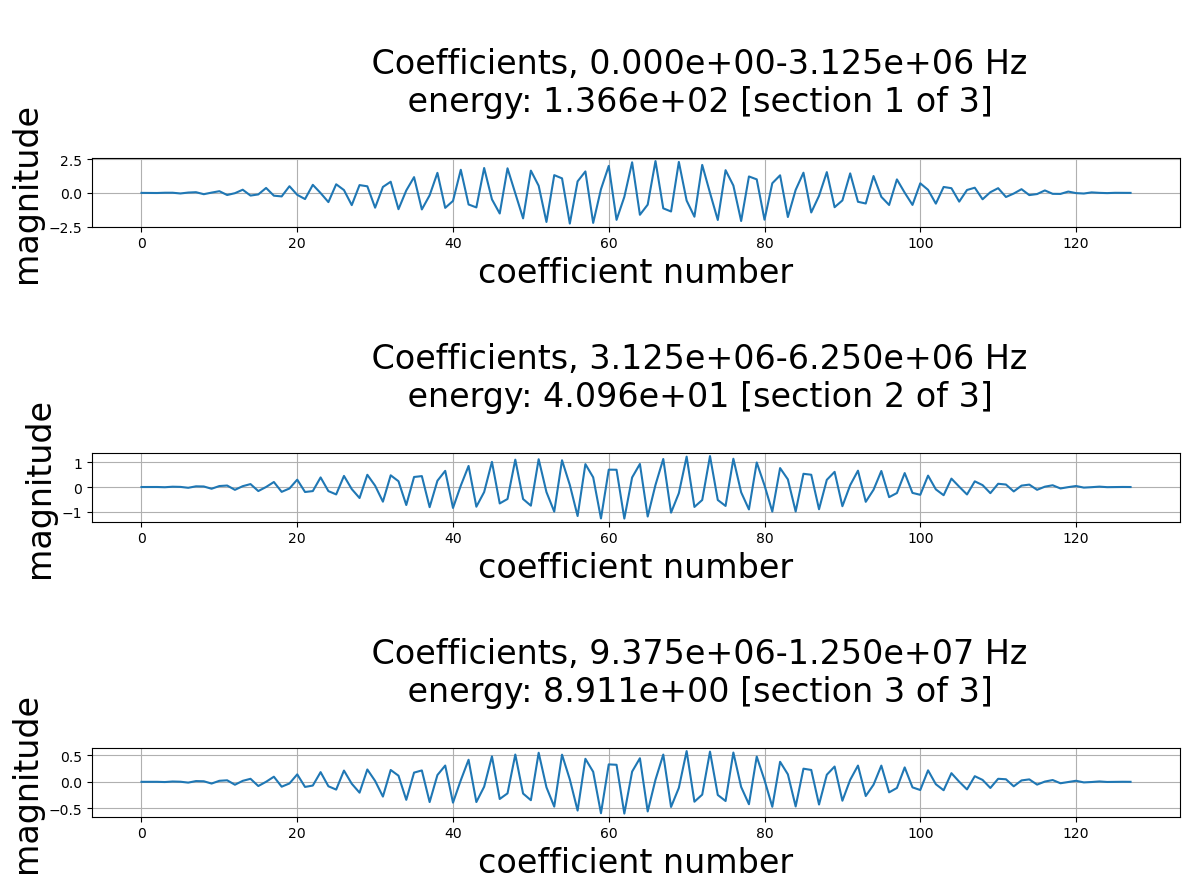

In [7]:
# find nodes with frequencies of interest
frequencies_of_interest = [1e6,1e7,0.5e7]

nodes_of_interest = transform_object.find_nodes(
    final_level_nodes,
    frequencies=frequencies_of_interest
)

# plot data from selected nodes
rows = int(len(nodes_of_interest))

fig,ax = plt.subplots(rows)
plot.plot_nodes(nodes_of_interest,ax,sampling_rate,rows,columns = 1)
fig.set_size_inches(12,3*rows)
fig.tight_layout()

## 2.1 Testing inverse transform

In [8]:
# transform
levels = 8
wavelet = 'db10'
sf = 50e6
freq = 2e6
amp_sin_waves = 1
phase = 0
signal_duration = 1000/sf
data, t_plot = sd.sound_wave(
    amp_sin_waves, frequency, phase, signal_duration, 
    sampling_rate=sf
)
data = data #  * blackmanharris(len(data))

fig = go.Figure()
fig.add_trace(go.Scatter(x=[i for i in range(len(data))], y=data, name="data"))

# Wavelet transform of the data
transform_object = wpt.dwpt(data, levels, wavelet)
transform_object.calc_frequencies(sampling_rate)

# inverse dwt
dwt_inverse = inv.inv_dwt(transform_object)
print('total error dwt:', sum(data - dwt_inverse))

# inverse dwpt
dwpt_inverse = inv.inv_dwpt(transform_object)
print('total error, packet', sum(np.array(data) - dwpt_inverse))
fig.add_trace(
    go.Scatter(
        x=[i for i in range(len(dwpt_inverse))], 
        y=dwpt_inverse, name="inverse", 
        line=dict(dash="dot")
    )
)
fig.show()

total error dwt: 5.333660486341631e-14
total error, packet 2.5147775495156872e-14


### Info Attributes
Info attributes display statistical measures at each node. InverseTransform.info() calculates these on the recovered signal at each node, while the Transform.info() function calculates these on the wavelet coefficinets at each node.

In [9]:
inv_transform_obj = inv.InverseTransform(transform_object)
inv_transform_obj.info(level=levels, order="freq")

,level,node number,norm frequency range,frequency range,centre frequency,energy,log energy,average energy,log average energy,kurtosis,crest factor,skewness,abs skewness,entropy,spectral entropy,level entropy
0,8,0,"(0, 0.00390625)","(0.000e+00, 9.766e+04)",4.882812e+04,4.031552e+00,6.054723,4.027525e-03,-23.949618,7.334299,4.070036,2.017678,2.017678,5.322518,0.399526,8.179299e-02
1,8,1,"(0.00390625, 0.0078125)","(9.766e+04, 1.953e+05)",1.464844e+05,2.158479e+00,3.341478,2.156322e-03,-26.662863,3.525030,2.460236,-0.112929,0.112929,5.935523,0.216167,4.913566e-02
2,8,3,"(0.0078125, 0.01171875)","(1.953e+05, 2.930e+05)",2.441406e+05,8.637123e-01,-0.636309,8.628494e-04,-30.640650,2.993187,2.360196,-0.098427,0.098427,6.089123,0.172594,2.150931e-02
3,8,2,"(0.01171875, 0.015625)","(2.930e+05, 3.906e+05)",3.417969e+05,2.297006e-01,-6.388379,2.294711e-04,-36.392720,4.097105,2.754734,-0.122814,0.122814,5.867778,0.274712,6.227145e-03
4,8,6,"(0.015625, 0.01953125)","(3.906e+05, 4.883e+05)",4.394531e+05,1.589174e-01,-7.988286,1.587586e-04,-37.992627,6.357981,3.340107,-0.293741,0.293741,5.369501,0.309941,4.266937e-03
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
251,8,134,"(0.98046875, 0.984375)","(2.451e+07, 2.461e+07)",2.456055e+07,7.893120e-07,-61.027513,7.885235e-10,-91.031854,9.380223,4.748292,-0.047460,0.047460,5.219200,0.422745,4.023746e-08
252,8,130,"(0.984375, 0.98828125)","(2.461e+07, 2.471e+07)",2.465820e+07,2.298902e-06,-56.384795,2.296606e-09,-86.389136,5.874950,3.396020,-0.001052,0.001052,5.588537,0.314418,1.139757e-07
253,8,131,"(0.98828125, 0.9921875)","(2.471e+07, 2.480e+07)",2.475586e+07,4.228790e-05,-43.737839,4.224566e-08,-73.742179,6.298863,3.321193,0.000401,0.000401,5.348659,0.286730,1.829952e-06
254,8,129,"(0.9921875, 0.99609375)","(2.480e+07, 2.490e+07)",2.485352e+07,5.488818e-05,-42.605212,5.483335e-08,-72.609553,5.196042,2.935757,-0.003435,0.003435,5.518295,0.297893,2.365204e-06


In [10]:
transform_object.info(level=levels)

,level,node number,norm frequency range,frequency range,centre frequency,energy,log energy,average energy,log average energy,kurtosis,crest factor,skewness,abs skewness,entropy,spectral entropy,level entropy
0,8,0,"(0, 0.00390625)","(0.000e+00, 9.766e+04)",4.882812e+04,718.477500,28.564132,32.658068,15.139905,2.535223,1.305583,-1.141322,1.141322,2.820841,0.302846,3.532747
1,8,1,"(0.00390625, 0.0078125)","(9.766e+04, 1.953e+05)",1.464844e+05,6.507078,8.133860,0.295776,-5.290367,3.585091,2.717319,0.387662,0.387662,2.147881,0.858867,0.084465
2,8,2,"(0.01171875, 0.015625)","(2.930e+05, 3.906e+05)",3.417969e+05,1.475999,1.690860,0.067091,-11.733367,2.802769,2.395206,-0.748754,0.748754,2.058295,0.811705,0.023275
3,8,3,"(0.0078125, 0.01171875)","(1.953e+05, 2.930e+05)",2.441406e+05,3.382835,5.292808,0.153765,-8.131418,2.336881,2.167397,0.058821,0.058821,2.430774,0.789411,0.050252
4,8,4,"(0.02734375, 0.03125)","(6.836e+05, 7.812e+05)",7.324219e+05,2.133761,3.291457,0.096989,-10.132770,2.070004,2.231755,-0.689495,0.689495,2.123514,0.641358,0.032352
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
251,8,251,"(0.67578125, 0.6796875)","(1.689e+07, 1.699e+07)",1.694336e+07,0.042341,-13.732370,0.001925,-27.156597,2.847855,2.227215,-0.406268,0.406268,2.223846,0.780111,0.000982
252,8,252,"(0.65625, 0.66015625)","(1.641e+07, 1.650e+07)",1.645508e+07,0.002146,-26.684605,0.000098,-40.108832,7.111401,3.338237,-2.181990,2.181990,1.397274,0.901484,0.000059
253,8,253,"(0.66015625, 0.6640625)","(1.650e+07, 1.660e+07)",1.655273e+07,0.055749,-12.537660,0.002534,-25.961887,2.623196,1.896738,-0.229214,0.229214,2.312232,0.535913,0.001273
254,8,254,"(0.66796875, 0.671875)","(1.670e+07, 1.680e+07)",1.674805e+07,0.048320,-13.158695,0.002196,-26.582922,2.884702,2.304443,-0.151578,0.151578,2.378277,0.828078,0.001123


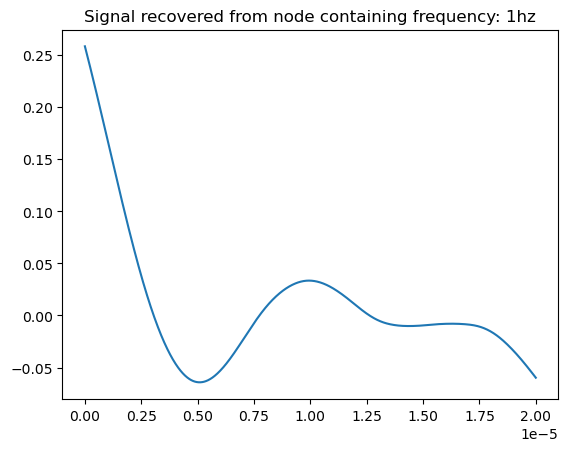

In [11]:
# Inverse transform from a single node
rec_0 = inv.inv_dwpt(transform_object, frequencies=1)
plt.plot(t_plot, rec_0)
plt.title("Signal recovered from node containing frequency: 1hz")
plt.show()

## 2.2 Testing inverse transform with synthetic data

The data is generated using the synthetic data package. Nodes are chosen for reconstruction and then the reconstructed sine wave is plotted alongside the transform results.

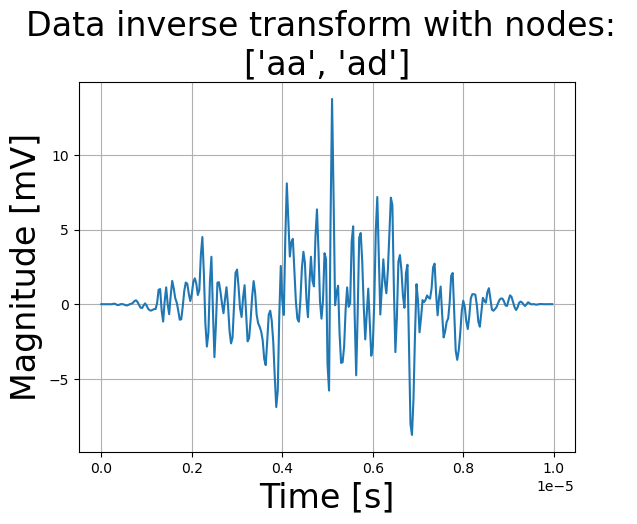

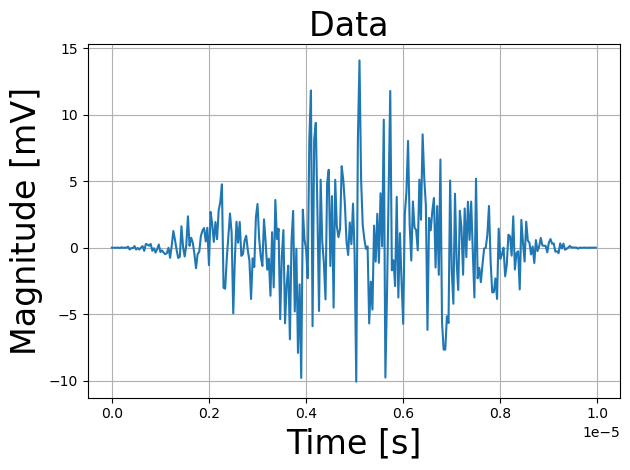

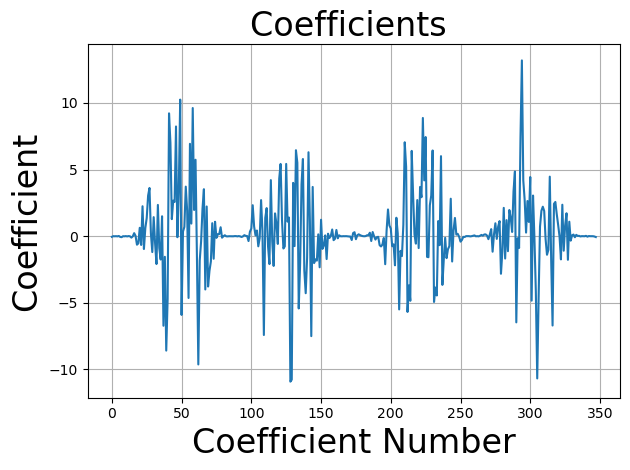

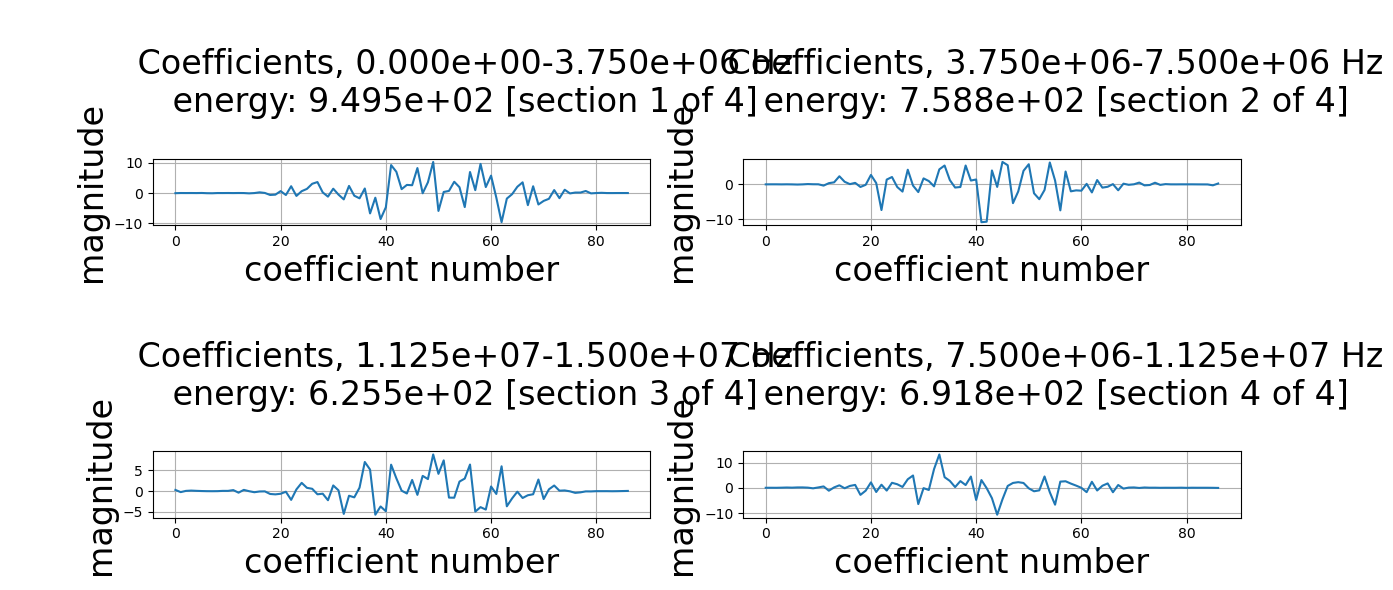

In [12]:
from numpy.random import seed

seed(seed = 1)

# set parameters for synthetic data
amp_sin_waves = 1 # amplitude of each sine wave that is added to the sound wave
sampling_rate = 30e6

test_frequencies = [1e6] # list of frequencies to test
harmonics = [1/4, 1/2, 1, 2, 3] # list of harmonics to test for each frequency

for frequency in test_frequencies:
    frequencies = frequency*np.array(harmonics)

    time_period = 1/frequency
    signal_duration = 10*time_period # signal duration is 10 times the period of the central frequency
    delay = 2*time_period # signal starts 2 time periods late
    end = 8*time_period # signal ends 2 time periods early

    gaussian_noise_std = 5 # set the standard devaition of the noise

    # generate data
    data, t_plot = sd.sound_wave(
        amp_sin_waves, frequencies, phase, signal_duration, 
        sampling_rate, delay, end
        )

    gaussian_noise = sd.noise(gaussian_noise_std, signal_duration, sampling_rate)
    data += gaussian_noise
    data = signal.windows.hann(len(data)) * data

    # set parameters for transform
    levels = 2
    db_order = 9
    wavelet = f'db{db_order}'

    # transform
    transform_object = wpt.dwpt(data, levels, wavelet)
    final_nodes = transform_object.get_level(levels) # collect nodes from the last level
    transform_object.calc_frequencies(sampling_rate) # calculate the frequency ranges for each node

    nodes = ["aa", "ad"]  
    # takes same keyword arguments as packet_nodes_for_rec
    inverse = inv.inv_dwpt(transform_object, nodes=nodes)

    # plot inverse transform
    title = f'inverse transform with nodes: \n{nodes}'
    fig, ax = plt.subplots()
    plot.plot_wave(inverse, t_plot, ax, title)
    plt.show()

    # plot initial wave and transform coefficients
    full_plot(final_nodes, data, t_plot, sampling_rate)

### 3.0 Minimum entropy decomposition

Testing the minimum entropy decomposition 

see matlab documentation at https://uk.mathworks.com/help/wavelet/ug/wavelet-packets.html#

In [13]:
sampling_rate = 25E6

std_noise = 0.01

wavelet = "db1"
levels = 4
mode = "zero"

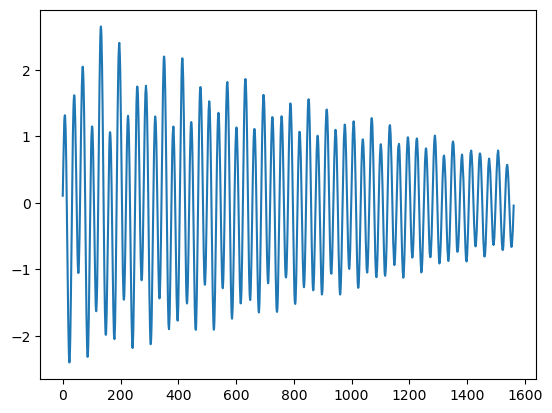

In [14]:
frequency = 8E5
pac = -1E5
R_init = 10E-6

min_energy = 0  # Only nodes with energy at least min_energy * total_energy will be considered

data = bdm.get_data(R_init, frequency, pac, sampling_rate)
data = (data - np.mean(data)) / np.std(data)
data += np.random.normal(0, std_noise, len(data))

plt.plot(data)
plt.show()

changed the entropy calculation to  remove the norm_energy

removed filter len from calc_max_level

Entropy of leaf nodes:
(4, 0) -0.0000
(4, 1) 0.0000
(3, 1) 0.0000
(2, 1) 0.0000
(1, 1) 0.0000

Shannon Entropy of all nodes:
(0, 0) 2.7726
(1, 0) 2.0794
(1, 1) 0.0000
(2, 0) 1.3863
(2, 1) 0.0000
(3, 0) 0.6931
(3, 1) 0.0000
(4, 0) -0.0000
(4, 1) 0.0000


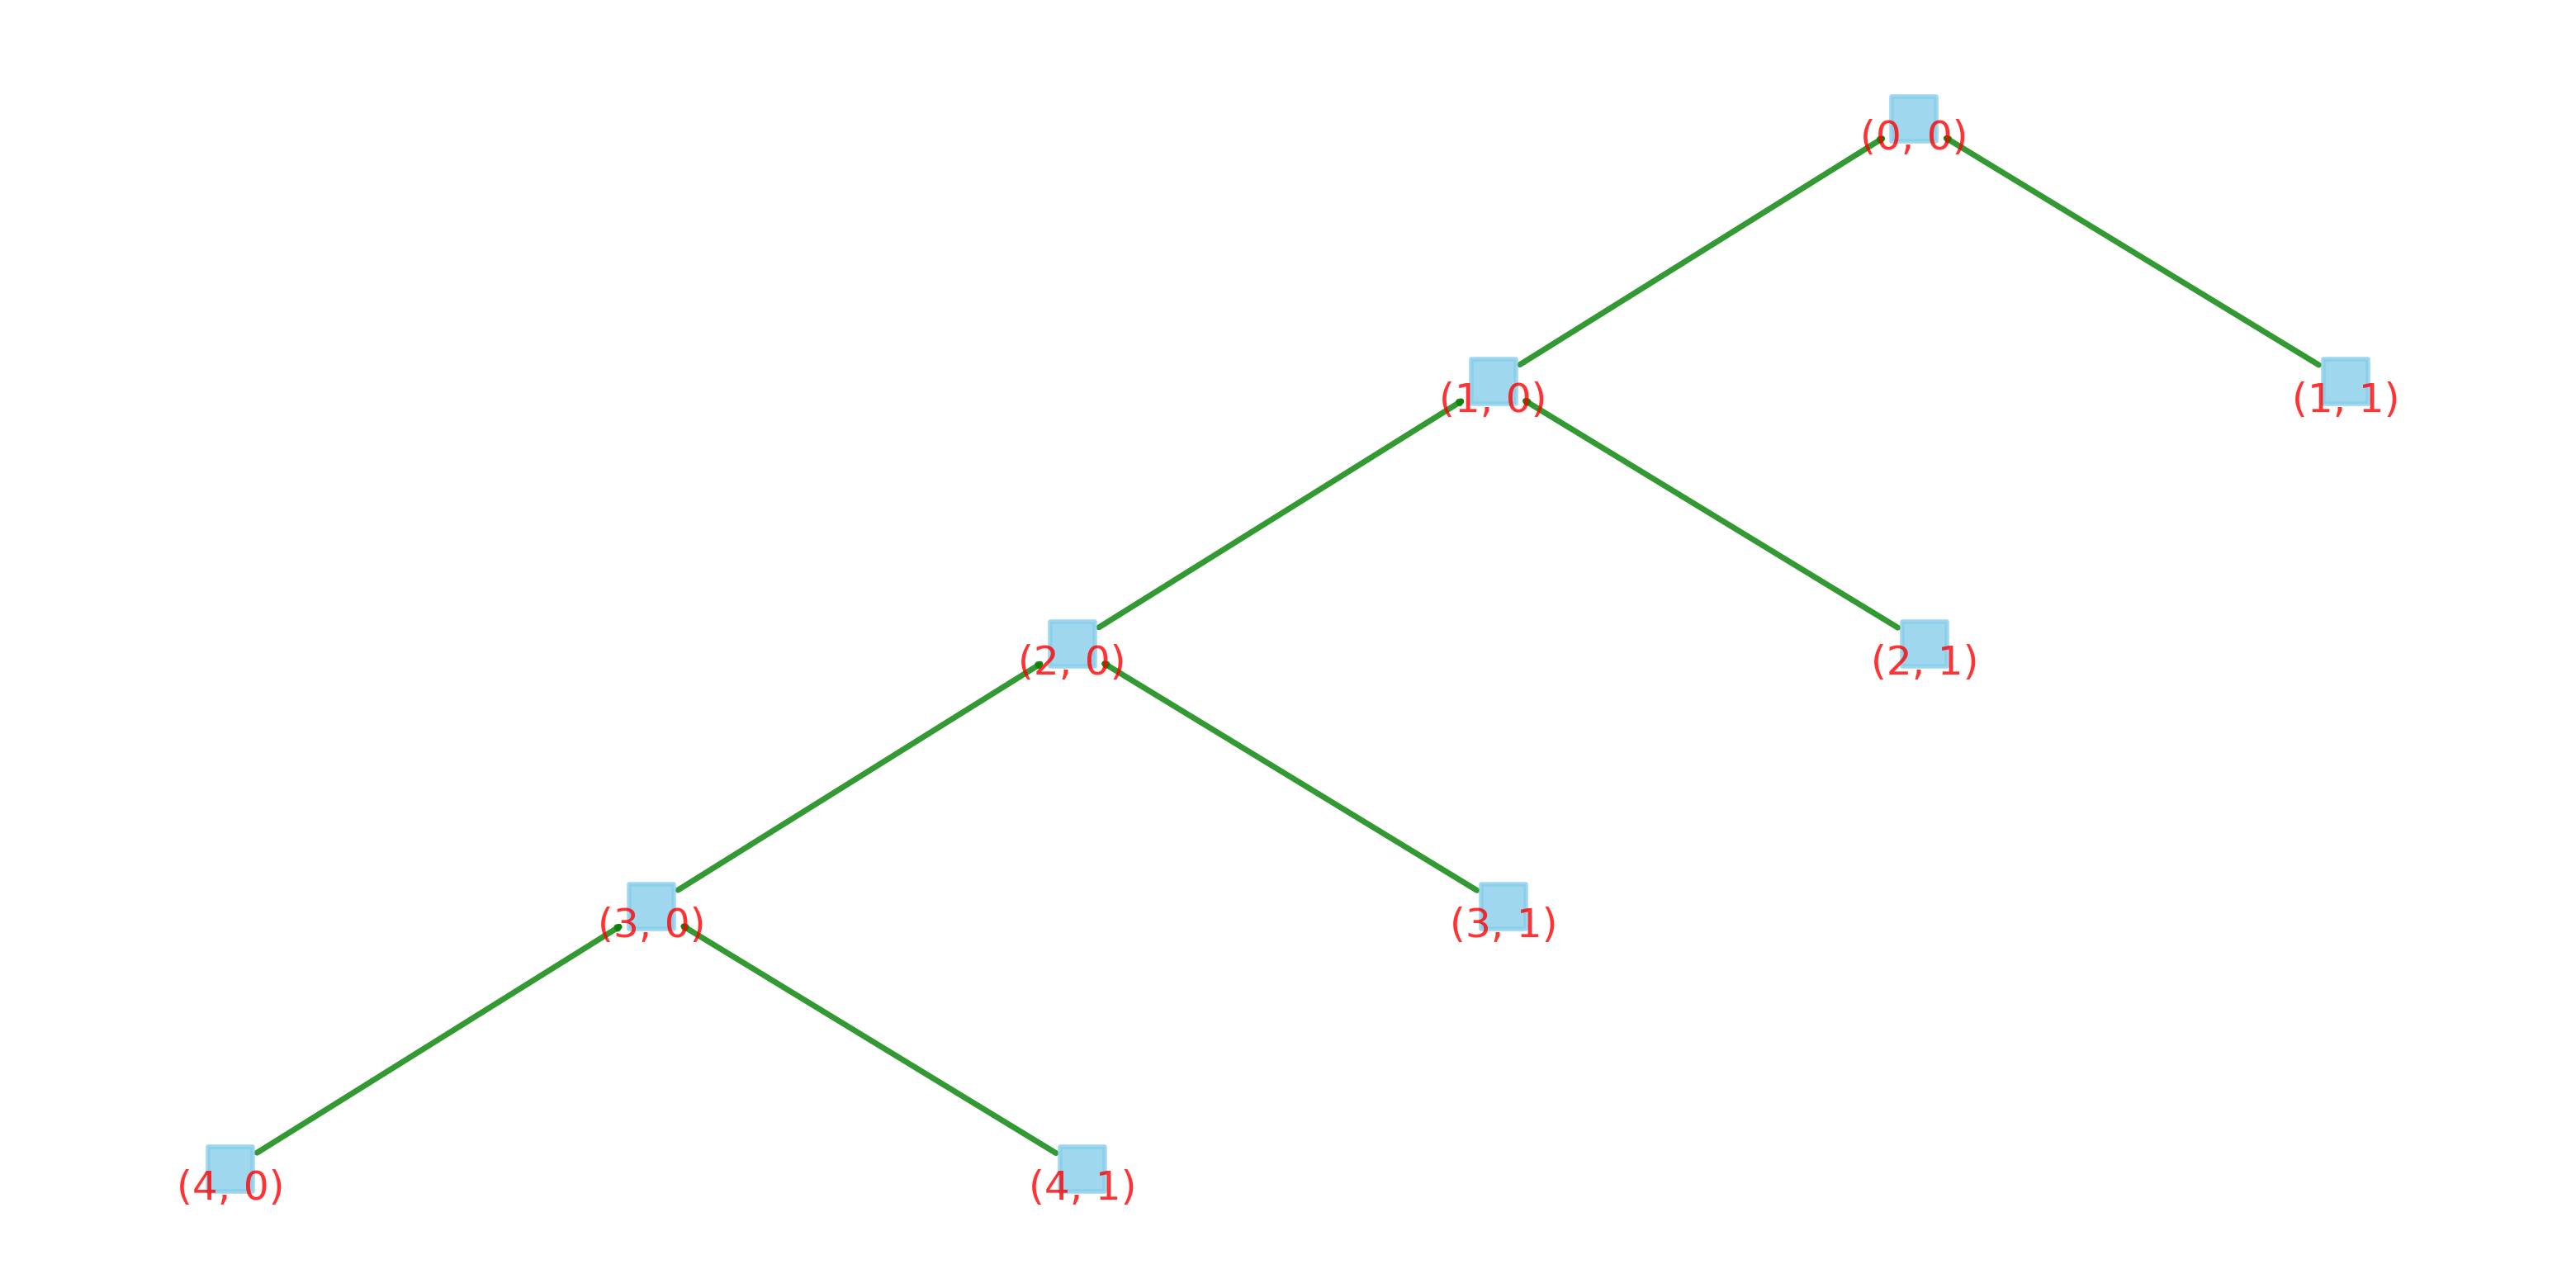

In [15]:
array = np.ones(16) * 0.25

tr_obj = wpt.dwpt(array, wavelet="haar", mode="zero", min_entropy=True)
print("Entropy of leaf nodes:")
for node in tr_obj.get_leaf_nodes(order="freq"):
    print((node.level, node.node_number), f"{node.level_entropy:.4f}")

print("\nShannon Entropy of all nodes:")
for level in tr_obj.levels:
    for node in tr_obj.get_level(level):
        print((node.level, node.node_number), f"{node.level_entropy:.4f}")

tr_obj.plot_tree()